=== FORWARD CHAINING STEPS ===
- Rule triggered: ['infection'] => fever
- Rule triggered: ['sore_throat'] => cough
- Rule triggered: ['fever', 'cough'] => flu
Result: SUCCESS

=== BACKWARD CHAINING STEPS ===
- To prove 'flu', must prove premises: ['fever', 'cough']
- To prove 'fever', must prove premises: ['infection']
- 'infection' is an initial fact.
- Successfully proved all premises for 'fever'.
- To prove 'cough', must prove premises: ['sore_throat']
- 'sore_throat' is an initial fact.
- Successfully proved all premises for 'cough'.
- Successfully proved all premises for 'flu'.
Result: SUCCESS



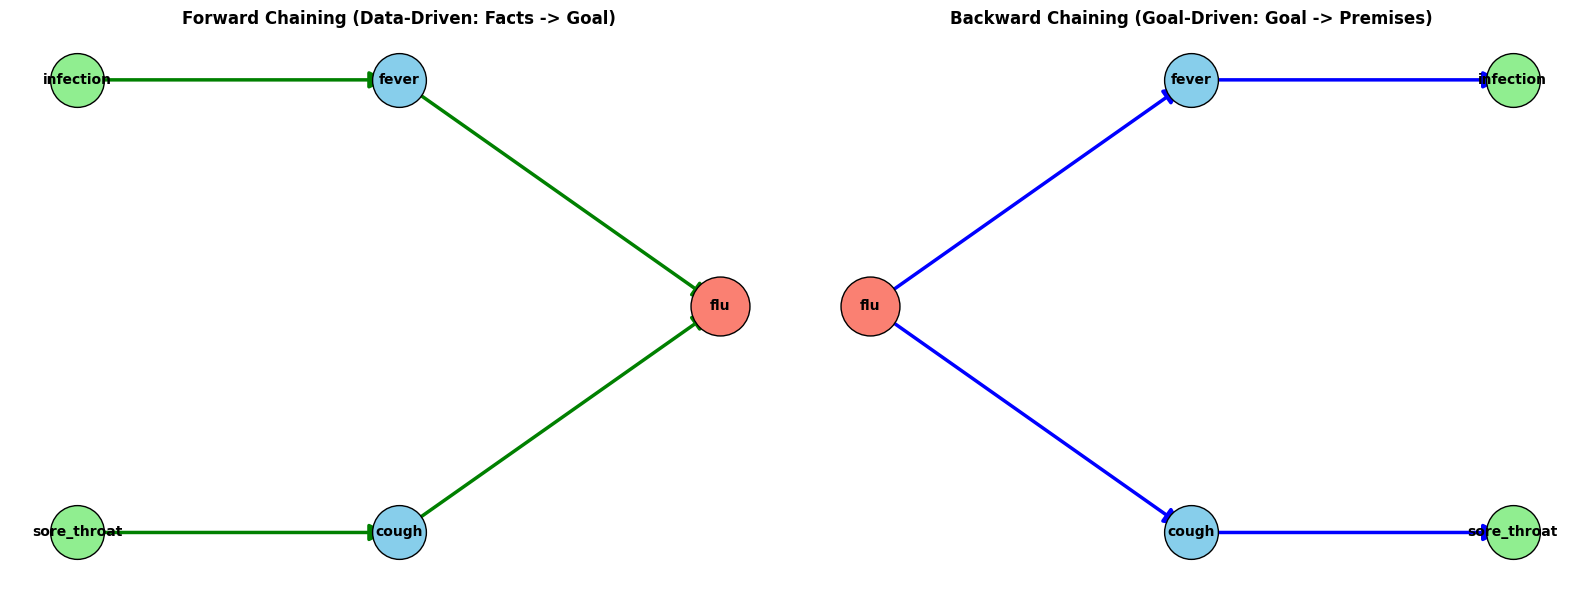

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

# --- 1. Knowledge Base and Rules Definition ---
class Rule:
    def __init__(self, premises, conclusion):
        self.premises = premises
        self.conclusion = conclusion

KB = [
    Rule(['fever', 'cough'], 'flu'),
    Rule(['infection'], 'fever'),
    Rule(['sore_throat'], 'cough')
]
initial_facts = {'infection', 'sore_throat'}
target = 'flu'

# --- 2. Forward Chaining Algorithm ---
def forward_chaining(kb, facts, goal):
    known = set(facts)
    added = True
    steps = []
    while added:
        added = False
        for rule in kb:
            if rule.conclusion not in known and all(p in known for p in rule.premises):
                known.add(rule.conclusion)
                steps.append(f"Rule triggered: {rule.premises} => {rule.conclusion}")
                added = True
                if rule.conclusion == goal:
                    return True, steps
    return False, steps

# --- 3. Backward Chaining Algorithm ---
def backward_chaining(kb, facts, goal, visited=None, steps=None):
    if visited is None:
        visited = set()
    if steps is None:
        steps = []

    if goal in facts:
        steps.append(f"'{goal}' is an initial fact.")
        return True, steps
    if goal in visited:
        return False, steps
    visited.add(goal)

    for rule in kb:
        if rule.conclusion == goal:
            steps.append(f"To prove '{goal}', must prove premises: {rule.premises}")
            all_proven = True
            for p in rule.premises:
                proven, steps = backward_chaining(kb, facts, p, visited.copy(), steps)
                if not proven:
                    all_proven = False
                    break
            if all_proven:
                steps.append(f"Successfully proved all premises for '{goal}'.")
                return True, steps
    return False, steps

# Run Algorithms
fc_success, fc_steps = forward_chaining(KB, initial_facts, target)
bc_success, bc_steps = backward_chaining(KB, initial_facts, target)

# Print Execution Steps
print("=== FORWARD CHAINING STEPS ===")
for step in fc_steps:
    print(f"- {step}")
print(f"Result: {'SUCCESS' if fc_success else 'FAILED'}\n")

print("=== BACKWARD CHAINING STEPS ===")
for step in bc_steps:
    print(f"- {step}")
print(f"Result: {'SUCCESS' if bc_success else 'FAILED'}\n")

# --- 4. Plotting Graphs Side-by-Side ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Forward Chaining Graph (Inference Direction)
G_fc = nx.DiGraph()
G_fc.add_edges_from([
    ('infection', 'fever'),
    ('sore_throat', 'cough'),
    ('fever', 'flu'),
    ('cough', 'flu')
])
pos_fc = {
    'infection': (0, 2), 'sore_throat': (0, 0),
    'fever': (1, 2), 'cough': (1, 0),
    'flu': (2, 1)
}

ax1.set_title("Forward Chaining (Data-Driven: Facts -> Goal)", fontsize=12, fontweight='bold')
x_nodes_fc = ['infection', 'sore_throat']
i_nodes_fc = ['fever', 'cough']
g_nodes_fc = ['flu']
nx.draw_networkx_nodes(G_fc, pos_fc, nodelist=x_nodes_fc, node_color='lightgreen', node_size=1500, edgecolors='black', ax=ax1)
nx.draw_networkx_nodes(G_fc, pos_fc, nodelist=i_nodes_fc, node_color='skyblue', node_size=1500, edgecolors='black', ax=ax1)
nx.draw_networkx_nodes(G_fc, pos_fc, nodelist=g_nodes_fc, node_color='salmon', node_size=1800, edgecolors='black', ax=ax1)
nx.draw_networkx_edges(G_fc, pos_fc, arrowstyle='-|>', arrowsize=25, edge_color='green', width=2.5, ax=ax1)
nx.draw_networkx_labels(G_fc, pos_fc, font_size=10, font_weight='bold', ax=ax1)
ax1.axis('off')

# Backward Chaining Graph (Sub-goal Expansion Direction)
G_bc = nx.DiGraph()
G_bc.add_edges_from([
    ('flu', 'fever'),
    ('flu', 'cough'),
    ('fever', 'infection'),
    ('cough', 'sore_throat')
])
pos_bc = {
    'flu': (0, 1),
    'fever': (1, 2), 'cough': (1, 0),
    'infection': (2, 2), 'sore_throat': (2, 0)
}

ax2.set_title("Backward Chaining (Goal-Driven: Goal -> Premises)", fontsize=12, fontweight='bold')
nx.draw_networkx_nodes(G_bc, pos_bc, nodelist=g_nodes_fc, node_color='salmon', node_size=1800, edgecolors='black', ax=ax2)
nx.draw_networkx_nodes(G_bc, pos_bc, nodelist=i_nodes_fc, node_color='skyblue', node_size=1500, edgecolors='black', ax=ax2)
nx.draw_networkx_nodes(G_bc, pos_bc, nodelist=x_nodes_fc, node_color='lightgreen', node_size=1500, edgecolors='black', ax=ax2)
nx.draw_networkx_edges(G_bc, pos_bc, arrowstyle='-|>', arrowsize=25, edge_color='blue', width=2.5, ax=ax2)
nx.draw_networkx_labels(G_bc, pos_bc, font_size=10, font_weight='bold', ax=ax2)
ax2.axis('off')

plt.tight_layout()
plt.show()